## Langchain for agentic AI

In [21]:
# check version of langchain
import langchain 
langchain.__version__

'1.3.17'

In [22]:
# load api keys from env file
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")

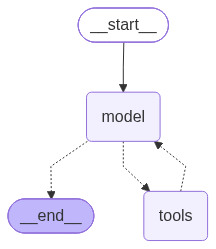

In [23]:
# create first agent using openai service provider
from datetime import datetime
from langchain.agents import create_agent
from geopy.geocoders import Nominatim

# define tool for agent
def get_city_cordinates(city: str) -> dict:
    """
    Gets the geographic coordinates and address for a given city name.
    
    Args:
        city (str): The name of the city to locate.
        
    Returns:
        dict: A dictionary containing City, Latitude, Longitude, and Address, or an error message.
    """
    locator  =  Nominatim(user_agent='city_coords_app')

    try:
        location = locator.geocode(city)
        if location:
            return {
                "City": location.city,
                "Latitude":location.Latitude,
                "Longitude":location.Longitude,
                "Address":location.Address
            }
        return {"message":f'City with name {city} not found.'}
    except Exception as e:
        return f'Encounter an error as: {e}'

agent = create_agent(
    model = 'gpt-5',
    tools=[get_city_cordinates],
    system_prompt='you are an expert system design engineer'
)
agent

In [24]:
agent.invoke({"message":[{"content":"Design a simple cache feature for backend"}]})

KeyboardInterrupt: 

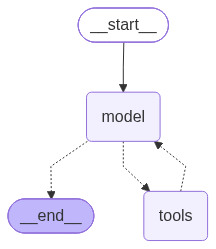

In [ ]:
# create first agent using google service provider
from datetime import datetime
from langchain.agents import create_agent
from geopy.geocoders import Nominatim

# define tool for agent
def get_city_cordinates(city_name: str):
    """
    Gets the geographic coordinates and address for a given city name.
    
    Args:
        city_name (str): The name of the city to locate.
        
    Returns:
        dict: A dictionary containing City, Latitude, Longitude, and Address, or an error message.
    """
    locator  =  Nominatim(user_agent='city_coords_app')

    try:
        location = locator.geocode(city_name)
        if location:
            return {
                "City": location.city,
                "Latitude":location.Latitude,
                "Longitude":location.Longitude,
                "Address":location.Address
            }
        return {"message":f'City with name {city_name} not found.'}
    except Exception as e:
        return f'Encounter an error as: {e}'

agent = create_agent(
    model = 'google_genai:gemini-3.6-flash',
    tools=[get_city_cordinates],
    system_prompt='you are an expert system design engineer'
)
agent

In [ ]:
response=agent.invoke({"messages": [{"role": "user", "content": "What's the location of Doda?"}]})

In [ ]:
response["messages"][-1].content_blocks[0]['text']

'**Doda** is a town and district located in the **Jammu region** of the union territory of **Jammu and Kashmir, India**.\n\n### Geographic Location & Context:\n* **Region:** Jammu Division, Jammu and Kashmir, India\n* **Geographic Coordinates:** Approximately **33.14° N** latitude, **75.54° E** longitude\n* **Elevation:** Around 1,107 meters (3,632 feet) above sea level\n* **Terrain:** Situated in the Middle Himalayas along the banks of the Chenab River. It is bordered by Kishtwar, Ramban, Udhampur, Kathua, and Chamba (Himachal Pradesh) districts.'

## Model Integration 

##### Gemini

In [ ]:
# Using init_chat_model
from langchain.chat_models import init_chat_model

agent = init_chat_model('google_genai:gemini-3.7-flash')

In [ ]:
response = agent.invoke("What is current AI trend")

In [ ]:
response.content

[{'type': 'text',
  'text': 'The current AI landscape is shifting rapidly from the initial hype of simple text-based chatbots toward **action-oriented, efficient, and multimodal systems**. \n\nHere are the top AI trends defining the industry right now:\n\n---\n\n### 1. Multimodal AI (Omni-Models)\nAI is no longer restricted to just text. The latest models natively process and generate text, audio, images, and video simultaneously in real time.\n* **Key examples:** OpenAI’s **GPT-4o**, Google’s **Gemini 1.5 Pro**.\n* **Why it matters:** This enables natural, fluid human-to-AI voice conversations with zero latency, real-time translation, and the ability to "see" via smartphone cameras to solve visual problems on the fly.\n\n### 2. Autonomous AI Agents\nThe industry is moving from *chatbots that answer questions* to *agents that execute tasks*.\n* **What they do:** Instead of just writing code or drafting an email, an agent can plan, use web browsers, call APIs, debug software, and execut

#### Using ChatGoogleGenerativeAI class of langchain

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model='gemini-3.8-flash') 


In [ ]:
model.invoke("what is python")

### Grok Model

In [ ]:
# Using init_chat_model

import os
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
agent = init_chat_model(
    model = "groq:qwen/qwen3.6-27b"
)

agent.profile

In [ ]:
agent.invoke("Write two lines about Agentic AI")

AIMessage(content='\n<think>\nThinking Process:\n\n1.  **Deconstruct the request:**\n    *   Topic: Agentic AI.\n    *   Format: Two lines.\n\n2.  **Brainstorm key concepts of Agentic AI:**\n    *   Autonomy: It acts on its own, not just generates text.\n    *   Goal-oriented: It has objectives and plans to achieve them.\n    *   Action: It interacts with tools, APIs, environments.\n    *   Reasoning: It breaks down tasks, makes decisions.\n    *   Evolution: From passive chatbots to active agents.\n\n3.  **Drafting potential lines (Iterative process):**\n    *   *Draft 1:* Agentic AI goes beyond simple responses by autonomously planning and executing complex tasks to achieve specific goals. It empowers machines to reason, use tools, and act independently within digital environments.\n        *   *Critique:* Too long? "Two lines" usually implies brevity, maybe a couplet or just two distinct sentences. The length is okay, but could be punchier.\n    *   *Draft 2:* Agentic AI transforms 

In [ ]:
# using langchain.chat_groq
from langchain_groq import ChatGroq

model = ChatGroq(
    model = "groq:qwen/qwen3.8-27b"
)
model.profile

In [ ]:
response=model.invoke("Tell me few lines about Groq model")
response.content_blocks

### Streaming vs Batching

#### Streaming

Most models can stream their output content while it is being generated. By displaying output progressively, streaming significantly improves user experience, particularly for longer responses. Calling stream() returns an iterator that yields output chunks as they are produced. You can use a loop to process each chunk in real-time:

In [ ]:
# Streaming vs Batching
for chunk in model.stream("Compare openai vs Groq model"):
    print(chunk.text, end = "|", flush = True)


#### Batch

Batching a collection of independent requests to a model can significantly improve performance and reduce costs, as the processing can be done in parallel:

In [ ]:
responses = model.batch(
    [
        "What is python's Langchain framework?",
        "What is culture of AI?",
        "What does batching in model invocation means?"
    ]
)

for response in responses:
    print(response, end="#*---------*#")


In [ ]:
# batching with config
model.batch(
    ["Why do parrots have colorful feathers?",
    "How do airplanes fly?",
    "What is quantum computing?"],
    config={
        'max_concurrency': 5,  # Limit to 5 parallel calls
    }
)

## Tools
Models can request to call tools that perform tasks such as fetching data from a database, searching the web, or running code. Tools are pairings of:\
    A schema, including the name of the tool, a description, and/or argument definitions (often a JSON schema)\
    A function or coroutine to execute.

In [ ]:
## Tools
import os
from langchain.chat_models import init_chat_model

model = init_chat_model(
    model='google_genai:gemini-3.5-flash-lite'
)


In [ ]:
# model without tools
model.invoke("What is rate limiting concept in API development")

In [ ]:
# model with tools ( weather forecast tool)
from httpx2 import query
from langchain.tools import tool
import os
import requests 
import json


base_url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": 52.52,
	"longitude": 13.41,
	"hourly": "temperature_2m",
}

@tool
def get_weather_info(base_url:str, query_params: dict):
    """
    Fetches weather data using the Open-Meteo API.
    
    Args:
        base_url (str): The base API endpoint.
        query_params (dict): The parameters for the API query, including latitude and longitude.
        
    Returns:
        dict: A JSON response containing weather forecast data.
    """
    response = requests.get(base_url, params=query_params)
    data = response.json()
    return data

model_with_tools = model.bind_tools([get_weather_info])



In [ ]:
response = model_with_tools.invoke("Get the weather details for Noida city")
print(response.content_blocks)

[{'type': 'tool_call', 'id': 'call_7473002', 'name': 'get_weather_info', 'args': {'base_url': 'https://api.openweathermap.org/data/2.5/weather', 'query_params': {'units': 'metric', 'q': 'Noida'}}}]


In [ ]:
for tool_call in response.tool_calls:
    print(f"Tool: {tool_call['name']}")
    print(f"Args: {tool_call['args']}")

Tool: get_weather_info
Args: {'base_url': 'https://api.openweathermap.org/data/2.5/weather', 'query_params': {'units': 'metric', 'q': 'Noida'}}


## Tool Execution Loops

In [ ]:
# Step 1: Model generates tool calls
messages = [{"role": "user", "content": "What is the weather in Noida?"}]
ai_message = model_with_tools.invoke(messages)

messages.append(ai_message)

# Step 2: Execute tools and collect results
for tool_call in ai_message.tool_calls:
    tool_result =  get_weather_info.invoke(tool_call)
    messages.append(tool_result)

# Step 3: Pass results back to model for final response
final_response = model_with_tools.invoke(messages)
print(final_response.text) 

## Messages
Messages are the fundamental unit of context for models in LangChain. They represent the input and output of models, carrying both the content and metadata needed to represent the state of a conversation when interacting with an LLM. Messages are objects that contain:

    1. Role - Identifies the message type (e.g. system, user)
    2. Content - Represents the actual content of the message (like text, images, audio, documents, etc.)
    3. Metadata - Optional fields such as response information, message IDs, and token usage
LangChain provides a standard message type that works across all model providers, ensuring consistent behavior regardless of the model being called.

In [ ]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

model = init_chat_model(
    model = 'groq:openai/gpt-oss-120b'
)


In [ ]:
response = model.invoke("What is limit for groq models in free tier")

In [ ]:
response

AIMessage(content='**Short answer:**  \nOn the current Groq free‑tier (as of\u202fSeptember\u202f2026) you get **up to\u202f2\u202fmillion tokens per month** and **a maximum of\u202f10\u202frequests per second (RPS)** across all the hosted models. The free tier also caps the total compute‑time to **≈\u202f5\u202fGPU‑hours per month** (the exact number is shown as “compute credits” in the dashboard). Once any of those three limits is hit, further calls are rejected until the quota resets at the start of the next month.\n\n---\n\n### Detailed breakdown\n\n| Resource | Free‑tier limit | How it’s measured | What happens when you hit it |\n|----------|----------------|-------------------|------------------------------|\n| **Tokens** | 2\u202fM tokens/month (input\u202f+\u202foutput) | Counted per request; a token ≈ 4\u202fcharacters of text. | API returns `429 Too Many Requests` with a message “token quota exceeded”. |\n| **Requests per second (RPS)** | 10\u202fRPS (burst up to 15\u202fRPS 

In [ ]:
from pprint import pprint
pprint(response.text)


('**Short answer:**  \n'
 'On the current Groq free‑tier (as of\u202fSeptember\u202f2026) you get **up '
 'to\u202f2\u202fmillion tokens per month** and **a maximum of\u202f10\u202f'
 'requests per second (RPS)** across all the hosted models. The free tier also '
 'caps the total compute‑time to **≈\u202f5\u202fGPU‑hours per month** (the '
 'exact number is shown as “compute credits” in the dashboard). Once any of '
 'those three limits is hit, further calls are rejected until the quota resets '
 'at the start of the next month.\n'
 '\n'
 '---\n'
 '\n'
 '### Detailed breakdown\n'
 '\n'
 '| Resource | Free‑tier limit | How it’s measured | What happens when you hit '
 'it |\n'
 '|----------|----------------|-------------------|------------------------------|\n'
 '| **Tokens** | 2\u202fM tokens/month (input\u202f+\u202foutput) | Counted '
 'per request; a token ≈ 4\u202fcharacters of text. | API returns `429 Too '
 'Many Requests` with a message “token quota exceeded”. |\n'
 '| **Requests

## Text Prompts
Text prompts are strings - ideal for straightforward generation tasks where you don’t need to retain conversation history.

Use text prompts when:

1. You have a single, standalone request
2. You don’t need conversation history
3. You want minimal code complexity

In [ ]:
model.invoke("What is langchain")

AIMessage(content='**LangChain** is an open‑source framework that makes it easier to build applications powered by large language models (LLMs) such as OpenAI’s GPT‑4, Anthropic’s Claude, LLaMA, etc.  \nInstead of writing ad‑hoc code that calls an LLM, parses the response, and then does something else, LangChain gives you reusable building blocks that you can “chain” together—hence the name.\n\n---\n\n## Core Concepts\n\n| Component | What it does | Typical use‑case |\n|-----------|--------------|------------------|\n| **LLM Wrapper** | A thin Python (or JavaScript/TypeScript) wrapper around an LLM API (OpenAI, Azure, Cohere, HuggingFace, …). | `ChatOpenAI(model="gpt‑4")` |\n| **PromptTemplate** | A templating system for prompts that can inject variables, few‑shot examples, system messages, etc. | `PromptTemplate.from_template("Summarize the following article:\\n{article}")` |\n| **Chain** | A deterministic pipeline of steps (prompt → LLM → post‑processing). Chains can be simple (singl

## Message Prompts
Alternatively, you can pass in a list of messages to the model by providing a list of message objects.

#### Message types

1. System message - Tells the model how to behave and provide context for interactions
2. Human message - Represents user input and interactions with the model
3. AI message - Responses generated by the model, including text content, tool calls, and metadata
4. Tool message - Represents the outputs of tool calls

### System Message
A SystemMessage represent an initial set of instructions that primes the model’s behavior. You can use a system message to set the tone, define the model’s role, and establish guidelines for responses.

### Human Message
A HumanMessage represents user input and interactions. They can contain text, images, audio, files, and any other amount of multimodal content.

### AI Message
An AIMessage represents the output of a model invocation. They can include multimodal data, tool calls, and provider-specific metadata that you can later access.

### Tool Message
For models that support tool calling, AI messages can contain tool calls. Tool messages are used to pass the results of a single tool execution back to the model.

In [ ]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage

messages = [
    SystemMessage("You are an expert Python Developer"),
    HumanMessage("How do you design a web-application")
]
respone = model.invoke(
    messages
)


In [ ]:
print(respone.content)

## Designing a Web‑Application – A Step‑by‑Step Blueprint  

Below is a practical, end‑to‑end roadmap that you can follow (and adapt) when you design a modern web‑application.  
It is written from the perspective of a Python‑centric team, but the concepts apply to any stack.

---

### 1. **Clarify the Product Vision & Requirements**

| Activity | Goal | Typical Artefacts |
|----------|------|-------------------|
| **Stakeholder Interviews** | Understand business goals, user personas, success metrics | Vision statement, user stories, KPI list |
| **Functional Requirements** | Define *what* the system does | Feature list, use‑case diagram, user‑story map |
| **Non‑Functional Requirements (NFRs)** | Define *how* the system behaves | Performance (latency, throughput), scalability, security, compliance, availability, maintainability |
| **Prioritisation** | Decide MVP vs. later phases | MoSCoW matrix, roadmap |

> **Tip:** Write user stories in the “As a … I want … so that …” format and att

In [ ]:
# creating history of converstation
ai_msg = AIMessage("I am an LLM model, and can help you with the day to day tasks! ")

messages = [
    SystemMessage('You are everyday helpful agent'),
    HumanMessage("What is 4+6"),
    ai_msg,
    HumanMessage("What is 5x8"),
    HumanMessage('What is earlier conversations we have, give me a sumamry')
]
response  = model.invoke(messages)

In [ ]:
print( response.content)

**Answer to your math question:**  
\(5 \times 8 = 40\)

**Summary of our earlier conversation:**

1. **You asked:** “What is 4+6?”  
   **My response:** I gave a generic statement about being a helpful assistant rather than providing the actual answer.

2. **You then asked:** “What is 5x8?”  
   **(This is the current question, answered above.)**

So far, the interaction has involved two arithmetic queries, and I’ve now provided the correct result for the second one. If you’d like the answer to the first question as well (it’s 10), or have any other tasks, just let me know!


In [ ]:
response.usage_metadata

{'input_tokens': 137,
 'output_tokens': 257,
 'total_tokens': 394,
 'output_token_details': {'reasoning': 102}}

In [ ]:
from langchain.messages import AIMessage
from langchain.messages import ToolMessage

# After a model makes a tool call
# (Here, we demonstrate manually creating the messages for brevity)
ai_message = AIMessage(
    content=[],
    tool_calls=[{
        "name": "get_weather",
        "args": {"location": "San Francisco"},
        "id": "call_123"
    }]
)

# Execute tool and create result message
weather_result = "Sunny, 72°F"
tool_message = ToolMessage(
    content=weather_result,
    tool_call_id="call_123"  # Must match the call ID
)

# Continue conversation
messages = [
    HumanMessage("What's the weather in San Francisco?"),
    ai_message,  # Model's tool call
    tool_message,  # Tool execution result
]
response = model.invoke(messages)  # Model processes the result

In [ ]:
response.content

'The current weather in San\u202fFrancisco is sunny with a temperature of about 72\u202f°F.'

In [ ]:
tool_message

ToolMessage(content='Sunny, 72°F', tool_call_id='call_123')

## Structured Output
Models can be requested to provide their response in a format matching a given schema. This is useful for ensuring the output can be easily parsed and used in subsequent processing. LangChain supports multiple schema types and methods for enforcing structured output.

- 1. **Pydantic**\
Pydantic models provide the richest feature set with field validation, descriptions, and nested structures.
- 2. **TypedDict**\
TypedDict provides a simpler alternative using Python’s built-in typing, ideal when you don’t need runtime validation.
- 3. **DataClasses**\
A data class is a class typically containing mainly data, although there aren’t really any restrictions. You create it using the @dataclass decorator

In [1]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
model = init_chat_model(
    model = 'groq:openai/gpt-oss-20b'
)


In [ ]:
# define a pydantic model 
from pydantic import BaseModel, Field

class Movie(BaseModel):
    title:str = Field(description="Title of the Movie",examples=['Red Sea','Avengers Endgame'])
    ratings:float = Field(description="Rating of the Movie out of 10", examples=[6.5,8.9,9.0])
    director:str = Field(description="Director of the Movie", examples=["Christopher Nolan", "Ross Brothers"])
    year:str = Field(description="Year of release of Movie", examples=["2021","2026"])
    duration:int = Field(description="Duration of Movie in minutes", examples=[160,300,270])


model_with_str_output = model.with_structured_output(Movie)
model_with_str_output


_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.0', 'langchain': '1.3.17'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002548D0442F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002548D044D70>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Movie', 'description': '', 'parameters': {'properties': {'title': {'description': 'Title o

In [ ]:
response = model_with_str_output.invoke("Can you give me details of Avengers Endgame")

In [ ]:
print(response)

title='Avengers: Endgame' ratings=8.4 director='Anthony Russo & Joe Russo' year='2019' duration=181


# Raw Message along side parsed output

In [ ]:
raw_parsed = model.with_structured_output(Movie, include_raw=True)

In [ ]:
respone_raw = raw_parsed.invoke("Gvie me details of Endgame dooms day movie")

In [20]:
from pprint import pprint
pprint(respone_raw)

{'parsed': Movie(title='Avengers: Endgame', ratings=8.4, director='Anthony Russo, Joe Russo', year='2019', duration=181),
 'parsing_error': None,
 'raw': AIMessage(content='', additional_kwargs={'reasoning_content': 'The user says: "Gvie me details of Endgame dooms day movie". They likely want details about the movie "Avengers: Endgame" (maybe "Doomsday" movie? But "Endgame dooms day movie" might refer to "Avengers: Endgame" and "Doomsday"? They might want details about the movie "Endgame" from the "Doomsday" film? Let\'s interpret: They want details of a movie named "Endgame" that is a "dooms day movie". Possibly "Avengers: Endgame" which is a doomsday event. Or "Endgame" (2018) but that is a different film. They might want details about "Avengers: Endgame" which is a superhero film, but not "doomsday". "Doomsday" is a 2008 film about a virus. The phrase "Endgame dooms day movie" could be a combination: "Endgame" and "Doomsday". They might want details on both? But the phrasing: "Gvie

# Nested Structure

In [6]:
# Defining nested structure
from pydantic import BaseModel, Field

class Actor(BaseModel):
    name: str = Field(description="Name of the actor", examples=["Chris", 'Jackie chain'])
    role: str = Field(description="Role of the actor in movie", examples=['Lead male actor','Mother of lead cast'])

class MovieDetails(BaseModel):
    title:str = Field(description="Title of the Movie",examples=['Red Sea','Avengers Endgame'])
    ratings:float = Field(description="Rating of the Movie out of 10", examples=[6.5,8.9,9.0])
    director:str = Field(description="Director of the Movie", examples=["Christopher Nolan", "Ross Brothers"])
    year:str = Field(description="Year of release of Movie", examples=["2021","2026"])
    duration:int = Field(description="Duration of Movie in minutes", examples=[160,300,270])
    cast:list[Actor]
    generes:list[str]
    budget:float | None = Field(description="Budget of the movie in millions USD", examples=[20, 100, 30])

model_with_str = model.with_structured_output(MovieDetails)


    

In [7]:
response = model_with_str.invoke("Give me details of Dhurandhar movie")

In [13]:
response

MovieDetails(title='Dhurandhar', ratings=7.0, director='Prakash Jha', year='2009', duration=140, cast=[Actor(name='Sanjay Dutt', role='Lead actor'), Actor(name='Shweta Bhardwaj', role='Lead actress'), Actor(name='Arjun Rampal', role='Supporting actor')], generes=['Drama', 'Thriller'], budget=10000000.0)

In [14]:
from pprint import pprint

pprint(response)

MovieDetails(title='Dhurandhar', ratings=7.0, director='Prakash Jha', year='2009', duration=140, cast=[Actor(name='Sanjay Dutt', role='Lead actor'), Actor(name='Shweta Bhardwaj', role='Lead actress'), Actor(name='Arjun Rampal', role='Supporting actor')], generes=['Drama', 'Thriller'], budget=10000000.0)


## TypeDict

In [15]:
from typing_extensions import TypedDict,Annotated

class MovieDict(TypedDict):
    """A movie with details."""
    title: Annotated[str, ..., "The title of the movie"]
    year: Annotated[int, ..., "The year the movie was released"]
    director: Annotated[str, ..., "The director of the movie"]
    rating: Annotated[float, ..., "The movie's rating out of 10"]


model_withtypedict=model.with_structured_output(MovieDict)
response=model_withtypedict.invoke("Please provide the details of the movie avengers")
response

{'director': 'Joss Whedon', 'rating': 8, 'title': 'The Avengers', 'year': 2012}

In [ ]:
class Actor(TypedDict):
    name: str
    role: str

class MovieDetails(TypedDict):
    title: str
    year: int
    cast: list[Actor]
    genres: list[str]
    budget: float | None = Field(None, description="Budget in millions USD")

model_with_structure = model.with_structured_output(MovieDetails)

response = model_with_structure.invoke("Provide details about the movie Avengers")
response

## DataClasses

In [ ]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent


class ContactInfo(BaseModel):
    """Contact information for a person."""
    name: str = Field(description="The name of the person")
    email: str = Field(description="The email address of the person")
    phone: str = Field(description="The phone number of the person")

agent = create_agent(
    model="gpt-5",
    response_format=ContactInfo  # Auto-selects ProviderStrategy
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "Extract contact info from: John Doe, john@example.com, (555) 123-4567"}]
})

result

In [ ]:
## Typedict
from typing_extensions import TypedDict
from langchain.agents import create_agent


class ContactInfo(TypedDict):
    """Contact information for a person."""
    name: str # The name of the person
    email: str # The email address of the person
    phone: str # The phone number of the person

agent = create_agent(
    model="gpt-5",
    response_format=ContactInfo  # Auto-selects ProviderStrategy
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "Extract contact info from: John Doe, john@example.com, (555) 123-4567"}]
})

result["structured_response"]
# {'name': 'John Doe', 'email': 'john@example.com', 'phone': '(555) 123-4567'}

In [ ]:
## Dataclass

from dataclasses import dataclass
from langchain.agents import create_agent

@dataclass
class ContactInfo:
    """Contact information for a person."""
    name: str # The name of the person
    email: str # The email address of the person
    phone: str # The phone number of the person


agent = create_agent(
    model="gpt-5",
    response_format=ContactInfo  # Auto-selects ProviderStrategy
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "Extract contact info from: John Doe, john@example.com, (555) 123-4567"}]
})

result["structured_response"]

###### End